# FarmTech Solutions · Fase 6 · **Ir Além 3.1**
## Coleta de imagens por câmera Wi-Fi e reconhecimento em tempo real com o `best.pt`

**Aluno:** Jefferson Gonçalves Lemos · RM 572399

| Material | Link |
|---|---|
| Vídeo de demonstração (até 5 min, não listado) | ⏳ `https://youtu.be/<inserir>` |
| Vídeo complementar sobre a escolha do Hailo | ⏳ `https://youtu.be/<inserir>` |
| Notebook principal (Entregas 1 e 2) | [`../JeffersonGoncalvesLemos_rm572399_pbl_fase6.ipynb`](../JeffersonGoncalvesLemos_rm572399_pbl_fase6.ipynb) |

Neste notebook documento a opção 3.1 do Ir Além. Levei o módulo de visão do **rover autônomo de pasto**
da FarmTech (classes `vaca`, `cobra`, `escorpiao`, `arvore`, `cerca` e `caneca`) para fora do Colab: uma câmera
coleta as imagens e as transmite por Wi-Fi, e um programa Python executado no VS Code reconhece os
objetos com o modelo que treinei na Entrega 1. A `caneca` foi acrescentada como sexta classe por ser o
objeto que tenho à mão para a demonstração ao vivo (seção 5.4); ela não dispara alerta. A seção 1
separa o que testei do que ficou implementado sem teste.

## 1. O que o enunciado pede e como atendi

A opção 3.1 do enunciado aceita uma **ESP32-CAM real** ou a **webcam do PC conectada ao Python lendo o `best.pt`**,
e descreve o fluxo: *coletar imagens em tempo real e transmitir para um Visual Code que reconheça os objetos*.

Organizei a solução em **dois modos que usam o mesmo cliente**:

- **BASE (o fluxo descrito no enunciado):** uma câmera coleta as imagens e as transmite como MJPEG por
  Wi-Fi; o `cliente_vscode.py`, executado no VS Code do PC, carrega o modelo da Entrega 1 e detecta os
  objetos. Testei esse fluxo com o **iPhone pelo Safari** como câmera Wi-Fi, servido pelo
  `camera_server.py` no Mac (seções 5.4 e 7.1). A ESP32-CAM, o Raspberry Pi 5 e a webcam do PC
  (`--fonte 0`) usam as mesmas rotas e estão implementados, mas não foram testados.
- **PLUS (extensão do que foi pedido):** a proposta é tirar a inferência do PC e levá-la para dentro do
  rover. Implementei o caminho para o Raspberry Pi 5 com a NPU **Hailo-8L** executar o mesmo modelo,
  compilado em `.hef`, e enviar por Wi-Fi o vídeo já anotado e as detecções em JSON, com o ONNX Runtime
  na CPU do Pi como plano B. **Esse caminho não foi executado no hardware até a entrega**: o `best.hef`
  não foi compilado e a seção 8 descreve o que pretendo medir, sem resultados.

| Caminho | Situação |
|---|---|
| iPhone (Safari) → Wi-Fi → `camera_server.py` no Mac → `cliente_vscode.py` (`best.onnx` em CoreML) → caixas de volta ao celular | testado no macOS (seção 7.1) |
| Vídeo como câmera e celular simulado (`ferramentas/simula_celular.py`), BASE e PLUS simulado no Mac | testados no macOS durante o desenvolvimento (seções 5.4 e 5.5) |
| Webcam do PC, ESP32-CAM, Raspberry Pi 5 (BASE e plano B) | implementados, não testados (o sketch da ESP32-CAM não foi compilado) |
| Pi 5 + Hailo-8L | implementado (código e guia de conversão), não executado no hardware |
| Linux e Windows | previstos no código (`pathlib`, `--dispositivo`, `--provedor`), sem teste |

A tabela abaixo relaciona cada requisito do enunciado com a parte do projeto que o atende.

| Requisito do enunciado | Onde está |
|---|---|
| Coleta e envio das imagens | `camera_server.py` (com `--fonte navegador`, o celular pela página `celular.html`; também Pi/PC), `esp32cam/esp32cam_stream.ino` (ESP32-CAM) → `cliente_vscode.py` |
| Integração Wi-Fi estável e eficiente | MJPEG sobre HTTP, keepalive, reconexão automática, RTT e latência medidos (seções 4, 6 e 7) |
| Escolha e justificativa do hardware | Seção 2 |
| Código organizado e comentado | Pasta `ir_alem/`, seção 4 |
| Figura da arquitetura | Seção 3 (`figuras/arquitetura.png`, de autoria própria) |
| Evidências e vídeo | Seção 7 (a seção 8 descreve o plus, que não foi executado) |

## 2. Justificativa das escolhas

### Câmera + Wi-Fi em vez de processar tudo no PC com um cabo
O rover se desloca pelo pasto, então a câmera precisa estar **nele**, longe do computador. Escolhi o
Wi-Fi porque é o enlace que já existe na sede da fazenda e não exige infraestrutura nova. O custo é uma
latência variável e eventuais quedas de sinal; por isso o cliente reconecta sozinho e registra a latência
de cada quadro.

### MJPEG sobre HTTP
- É o formato nativo da ESP32-CAM: o sensor OV2640 já entrega JPEG e o microcontrolador apenas repassa os bytes.
- Abre em qualquer navegador, no VLC e no OpenCV, o que simplifica a depuração: basta abrir uma URL.
- Cada quadro é independente. Um pacote perdido compromete apenas um quadro, e não um trecho do vídeo,
  como acontece com H.264. Em troca, cada quadro consome mais banda.

### Celular como câmera Wi-Fi na demonstração ao vivo
Para gravar a demonstração, usei o celular como câmera Wi-Fi. A ideia inicial era um app de câmera IP,
mas o iPhone que uso não permite instalar apps. Por isso, o `camera_server.py` passou a servir uma
página (`/celular`) que o Safari abre e que envia os quadros da câmera por HTTPS ao Mac (seção 5.4).
A vantagem é a câmera de boa qualidade, que pode ser levada até o objeto sem cabo e sem app.
Diferentemente dos apps de câmera IP, que não enviam o `X-Timestamp` nem respondem a `/saude`, essa
fonte mantém todas as métricas do log, inclusive a latência fim a fim, com o relógio do celular
corrigido por um offset estimado pela própria página.

### ESP32-CAM × Raspberry Pi 5 × Pi 5 + Hailo-8L

| | ESP32-CAM | Raspberry Pi 5 | Pi 5 + Hailo-8L (plus) |
|---|---|---|---|
| Papel | só câmera + Wi-Fi | câmera + Wi-Fi + Linux | câmera + Wi-Fi + **inferência embarcada** |
| Processamento | microcontrolador de 240 MHz, PSRAM de 4 MB | CPU ARM de 4 núcleos | CPU + NPU de **13 TOPS** |
| Roda o YOLOv5 do projeto? | não (memória insuficiente) | previsto: sim, devagar (ONNX na CPU) | previsto: sim, em tempo real (INT8) |
| Depende do PC no campo? | sim | sim (modo BASE) | **não**: só as detecções e os alertas trafegariam |
| Situação neste trabalho | implementado, não testado | implementado, não testado | implementado, não executado no hardware |
| Quando faz sentido | protótipo barato, câmera fixa | câmera com mais controle (foco, exposição e resolução) | rover autônomo operando em campo |

**Decisão:** demonstro o fluxo pedido no enunciado no modo BASE, com o iPhone pelo Safari como câmera
Wi-Fi; as outras câmeras usam o mesmo contrato de rotas e ficaram implementadas para a etapa seguinte.
O plus com Hailo, implementado e não executado no hardware, trata a etapa seguinte do cenário da
FarmTech: o rover reconhecer os objetos no pasto sem um computador por perto. Escolhi o Hailo-8L por
motivos técnicos:

- **Inferência local:** o modelo roda no próprio rover, sem depender do PC nem de conexão com a nuvem,
  e as imagens não precisam sair do dispositivo.
- **Latência:** a expectativa é que a NPU execute o YOLOv5 quantizado em INT8 em poucos milissegundos
  por quadro; é o que pretendo medir na seção 8, comparando com a CPU do Pi.
- **Desempenho por consumo:** são 13 TOPS com consumo de poucos watts, compatível com a alimentação de
  um equipamento embarcado.
- **Rede:** com a inferência no rover, o Wi-Fi deixaria de ser crítico para a detecção; uma queda de
  sinal atrasaria o envio dos alertas, mas não interromperia o reconhecimento.

Detalho essa escolha no vídeo complementar sobre a escolha do Hailo, ⏳ `https://youtu.be/<inserir>`.

### Limitações assumidas
- A latência fim a fim usa o relógio da câmera (`X-Timestamp`) e só é confiável quando a câmera e o PC
  estão sincronizados por NTP. Sem essa sincronização, a métrica de referência passa a ser o **RTT**
  medido pelo próprio cliente.
- No celular pelo navegador, a latência fim a fim depende do offset de relógio estimado pela página
  (incerteza de ±RTT/2) e não inclui o atraso interno da câmera do celular, anterior à entrega do quadro
  ao navegador. O certificado autoassinado exige aceitar o aviso do navegador a cada novo IP do Mac.
- Escolhi transportar quadros JPEG por HTTPS por simplicidade e porque cada quadro leva o seu próprio
  `X-Timestamp`, o que permite medir a latência quadro a quadro. Uma evolução possível é o WebRTC, que
  envia vídeo contínuo com codec e consome menos banda, mas exige o mesmo HTTPS e acrescenta
  dependências como o `aiortc`.
- O modelo foi treinado com cerca de 32 imagens por classe. Em vídeo ao vivo, espero detecções que
  oscilam entre quadros, principalmente de `escorpiao`.
- A quantização INT8 do Hailo pode reduzir a precisão nas classes pequenas. Como o `best.hef` não foi
  compilado, esse efeito não foi medido; a seção 8 descreve como pretendo medi-lo.

## 3. Arquitetura

![Arquitetura do Ir Além](figuras/arquitetura.png)

*Figura de autoria própria (`figuras/arquitetura.svg`). A faixa verde mostra o fluxo pedido no enunciado
e a faixa azul, o plus embarcado; as duas trilhas chegam ao mesmo cliente no VS Code. Traço contínuo e
selo verde marcam o caminho que testei: iPhone pelo Safari → Wi-Fi → `camera_server.py` no Mac →
`cliente_vscode.py` → caixas de volta à tela do celular. Traço tracejado e selo cinza marcam o que está
implementado e não foi testado: ESP32-CAM, Raspberry Pi 5, webcam do PC e todo o modo PLUS com o Hailo-8L.*

## 4. Componentes

```
ir_alem/
├── camera_server.py          # câmera → Wi-Fi (Pi ou PC); modo PLUS com --inferencia hailo|onnx
├── celular.html              # página /celular: câmera do celular pelo navegador (--fonte navegador)
├── cliente_vscode.py         # PC: recebe, detecta (best.pt ou .onnx), alerta e grava os logs
├── exportar_modelo.py        # best.pt → best.onnx (opset 11, entrada do Hailo DFC) e, opcionalmente, CoreML
├── modelos/
│   └── best_portavel.pt      # modelo oficial da Entrega 1 (versionado); best.pt e best.onnx ficam fora do git
├── backends/                 # inferência embarcada com interface comum detect(frame) -> lista
│   ├── __init__.py           #   6 classes, cores e função anotar()
│   ├── yolo_utils.py         #   letterbox, decodificação do YOLOv5 e NMS em numpy
│   ├── onnx_backend.py       #   plano B: ONNX Runtime (CPU, CoreML, CUDA ou DirectML)
│   ├── compat.py             #   carga do best.pt do Colab em outro Python ou sistema operacional
│   └── hailo_backend.py      #   plus: HailoRT na NPU Hailo-8L (não executado no hardware)
├── ferramentas/simula_celular.py  # simula a página /celular com um vídeo (testes sem celular)
├── esp32cam/esp32cam_stream.ino   # ESP32-CAM: /frame.jpg e /saude na porta 80, /stream na 81 (não compilado)
├── hailo/README_conversao.md      # best.pt → ONNX → .hef (plano, não executado)
├── figuras/arquitetura.svg / .png
├── certs/                    # certificado autoassinado do --https (gerado, fora do git)
├── prints/                   # quadros salvos com a tecla s e capturas da demonstração
└── logs/                     # frames.csv e alertas.csv da sessão com o iPhone (versionados)
```

### 4.1 Transmissão: o mesmo contrato em todas as câmeras
Defini as mesmas rotas para todas as câmeras, de modo que o cliente não precisa saber qual hardware
está do outro lado:

| Rota | Conteúdo |
|---|---|
| `/stream` | MJPEG contínuo; cada quadro novo leva `X-Timestamp` (instante da captura) e, na fonte navegador, `X-Quadro` (número do quadro do celular). Sem quadro novo por 0,5 s, o último é reenviado com `X-Keepalive` |
| `/frame.jpg` | um quadro |
| `/saude` | JSON de status, usado para medir o RTT |
| `/deteccoes` (`GET`) | detecções em pixels (só no modo PLUS); com `?formato=normalizado`, as detecções mais recentes em coordenadas 0–1, em qualquer modo |
| `/deteccoes` (`POST`) | só com `--fonte navegador` no modo BASE: o cliente devolve as detecções normalizadas de cada quadro |
| `/celular` | página que transforma o navegador do celular em câmera (só com `--fonte navegador`) |
| `/quadro` | `POST` de um JPEG vindo da página, com `X-Timestamp` (ms) e o offset de relógio estimado; a resposta traz as detecções normalizadas mais recentes |
| `/qr.svg` | QR code com a URL de `/celular` |

Na ESP32-CAM, as rotas `/stream`, `/frame.jpg` e `/saude` têm os mesmos nomes, mas o `/stream` fica em
um servidor separado, na porta 81 (seção 5.3).

No trecho abaixo, do `camera_server.py`, cada quadro novo libera todas as conexões abertas, e nenhuma
delas recebe o mesmo quadro duas vezes como quadro novo. Se nenhum quadro chega em `KEEPALIVE` (0,5 s),
o servidor reenvia o último marcado com `X-Keepalive`, o que mantém a conexão viva sem que o cliente o
conte como quadro novo:
```python
with estado.cond:                        # aguarda um quadro novo para não reenviar o mesmo
    novo = estado.cond.wait_for(lambda: estado.numero != visto, timeout=KEEPALIVE)
    jpeg, visto, ts, quadro = estado.jpeg, estado.numero, estado.ts, estado.quadro_fonte
    novo = novo and jpeg is not None and time.time() - estado.publicado < 1.0
if novo:
    extra = f"X-Timestamp: {ts:.6f}\r\n" + (f"X-Quadro: {quadro}\r\n" if quadro else "")
else:
    jpeg, extra = jpeg or espera_jpeg, "X-Keepalive: 1\r\n"
self.wfile.write(
    f"--{FRONTEIRA}\r\nContent-Type: image/jpeg\r\n"
    f"Content-Length: {len(jpeg)}\r\n{extra}\r\n".encode())
```

### 4.2 Recepção e reconhecimento: `cliente_vscode.py`
O cliente interpreta o multipart por conta própria, em vez de usar `cv2.VideoCapture`, para ter acesso
ao `X-Timestamp`, ao `X-Quadro` e ao `X-Keepalive`. Se o Wi-Fi cair, ele imprime uma única mensagem e
tenta reconectar em segundo plano, com espera crescente entre as tentativas (0,5 s, 1 s, 2 s e 4 s, e
depois a cada 5 s), sem travar a janela. No modo BASE, o
`best.pt` é carregado pelo hub do YOLOv5; o `trust_repo=True` evita a confirmação interativa que as
versões recentes do PyTorch pedem ao baixar o repositório. A carga fica dentro de
`carregamento_portavel()` (`backends/compat.py`), que contorna as diferenças de versão do Python e de
sistema operacional entre o treino no Colab e o PC (detalhes na seção 5.1):
```python
with carregamento_portavel():
    self.modelo = torch.hub.load("ultralytics/yolov5", "custom", path=str(caminho), device=disp,
                                 trust_repo=True)
resultado = self.modelo(frame[:, :, ::-1])            # o hub espera RGB
```
Detecções de `cobra` e `escorpiao` acendem uma faixa vermelha de alerta e geram uma linha em
`alertas.csv`. Cada quadro gera uma linha em `frames.csv`, que é a base da análise das seções 6 e 7.

### 4.3 Inferência embarcada: `backends/`
Reimplementei em numpy o pós-processamento do YOLOv5 (letterbox, decodificação e NMS por classe) para
que o Pi execute a inferência **sem PyTorch**. O backend ONNX confere, ao carregar o modelo, se o número
de classes da saída (`5 + nc`) bate com a lista de nomes informada; sem essa checagem, um modelo COCO
lido com os nomes do projeto produziria rótulos errados sem nenhum erro. Escrevi o backend Hailo para
usar o NMS do próprio chip quando o `.hef` é compilado com o config `yolov5s` do Model Zoo (detalhes em
`hailo/README_conversao.md`). Ele não foi executado no hardware, então esse comportamento é o esperado
pela documentação do HailoRT, e não um resultado verificado. A opção `--classes coco` foi prevista para
validar o pipeline com um `.hef` pré-treinado no COCO antes de compilar o `best.hef` do projeto.

## 5. Como executar

Todos os comandos desta seção são executados **dentro de `ir_alem/`** (`cd ir_alem`), porque os
caminhos usados (`modelos/`, `logs/`, `prints/`, `backends/`) são relativos a essa pasta.

### 5.1 Instalação por sistema operacional
Desenvolvi e testei apenas no macOS (Apple Silicon). O cliente e os scripts foram escritos para rodar
também em Linux e Windows (usam `pathlib` e o próprio interpretador Python, sem comandos de shell), mas
não os executei nesses sistemas. A diferença prevista entre eles está na ativação do ambiente virtual e
no pacote do ONNX Runtime:

| Sistema | Ambiente e dependências (dentro de `ir_alem/`) |
|---|---|
| macOS (Apple Silicon) | `python3 -m venv .venv` · `source .venv/bin/activate` · `pip install -r requirements-pc.txt` |
| Linux | os mesmos comandos do macOS; com GPU NVIDIA, trocar `onnxruntime` por `onnxruntime-gpu` e instalar o PyTorch com CUDA (seletor de pytorch.org) |
| Windows (PowerShell) | `py -3.12 -m venv .venv` · `.venv\Scripts\Activate.ps1` · `pip install -r requirements-pc.txt`; com GPU, trocar `onnxruntime` por `onnxruntime-directml` (qualquer GPU DirectX 12) ou `onnxruntime-gpu` (NVIDIA) |

Com o ambiente ativo, os comandos abaixo são os mesmos nos três sistemas (`python ...`). O modelo
oficial da Entrega 1 está versionado em **`modelos/best_portavel.pt`**. O `best.pt` original do Colab e o
`best.onnx` ficam fora do git. O `best.onnx`, usado pelo cliente sem PyTorch, pelo plano B e como entrada
do Hailo DFC, é gerado a partir do arquivo versionado:
```
python exportar_modelo.py --pesos modelos/best_portavel.pt                   # modelos/best.onnx (opset 11, 640 px)
python exportar_modelo.py --pesos modelos/best_portavel.pt --formato ambos   # no Mac, também modelos/best.mlpackage (CoreML)
python exportar_modelo.py --pesos modelos/best.pt --so-portavel              # a partir do best.pt do Colab: só a cópia best_portavel.pt
```
O nome de saída descarta o sufixo `_portavel`, por isso o ONNX sai como `modelos/best.onnx`. Quando os
pesos de entrada são o `best.pt` original, o script grava antes, ao lado deles, a cópia
`best_portavel.pt`, e é ela que segue para o `export.py`. Essa etapa existe porque treinei no Colab com Python 3.13 em Linux, e o checkpoint do
YOLOv5 guarda um objeto `pathlib` entre os argumentos do treino: em Python 3.12 ele aponta para o módulo
`pathlib._local`, que não existe nessa versão, e no Windows ele é um `PosixPath`, que o sistema não
consegue instanciar. Na cópia, esses objetos foram convertidos para texto, e ela carrega em qualquer
versão do Python e em qualquer sistema operacional (verifiquei no macOS; nos outros sistemas é o
comportamento esperado); é o arquivo que versiono em `modelos/`. O `cliente_vscode.py` aplica o mesmo ajuste em memória ao abrir o `best.pt` original, então
os dois arquivos funcionam no modo BASE.

### 5.2 Onde a inferência roda: `--dispositivo` e `--provedor`
Deixei o hardware de inferência parametrizável, porque o mesmo cliente precisa aproveitar a GPU do Mac
em que desenvolvi e as GPUs de quem for executar em Windows ou Linux:

| Parâmetro | Vale para | Valores | O que `auto` escolhe |
|---|---|---|---|
| `--dispositivo` | `best.pt` (PyTorch, `cliente_vscode.py`) | `auto`, `cpu`, `mps`, `cuda` | CUDA > MPS > CPU |
| `--provedor` | `best.onnx` (ONNX Runtime, `cliente_vscode.py` e `camera_server.py`) | `auto`, `cpu`, `coreml`, `cuda`, `directml` | CUDA > CoreML > DirectML > CPU |

| Sistema | `best.pt` | `best.onnx` |
|---|---|---|
| macOS (Apple Silicon) | `--dispositivo mps` | `--provedor coreml` (já incluso no `onnxruntime`) |
| Linux ou Windows com NVIDIA | `--dispositivo cuda` | `--provedor cuda` (`onnxruntime-gpu`) |
| Windows sem NVIDIA | `--dispositivo cpu` | `--provedor directml` (`onnxruntime-directml`) |
| Qualquer sistema sem GPU, Raspberry Pi | `--dispositivo cpu` | `--provedor cpu` |

No `onnxruntime`, a CPU fica sempre como reserva para os operadores que o acelerador não suporta. Um
provedor pedido explicitamente e não instalado gera erro com a lista dos disponíveis, em vez de cair
na CPU sem aviso. O cliente imprime no início o que foi efetivamente usado (por exemplo,
`execução onnx:CoreMLExecutionProvider` ou `execução pt:mps`) e grava o mesmo valor na coluna
`execucao` do `frames.csv`. No modo PLUS, o valor vem do `/saude` do servidor (por exemplo,
`remoto:onnx:CPUExecutionProvider`). A análise da seção 6 separa os resultados por essa coluna.

### 5.3 Cenários

| Cenário | Situação | Câmera | PC (terminal do VS Code) |
|---|---|---|---|
| BASE · iPhone pelo Safari (sem app) | **testado** (macOS, seção 7.1) | no Mac: `python camera_server.py --fonte navegador`; no celular: abrir `https://<IP do Mac>:8000/celular` | `python cliente_vscode.py --fonte https://<IP do Mac>:8000/stream --inseguro --modelo modelos/best.onnx` |
| BASE · `.onnx` no PC, sem PyTorch | **testado** com o iPhone (CoreML) | qualquer uma das câmeras | `python cliente_vscode.py --fonte <URL> --modelo modelos/best.onnx --provedor auto` |
| BASE · webcam do PC | não testado | não se aplica | `python cliente_vscode.py --fonte 0 --modelo modelos/best_portavel.pt` |
| BASE · ESP32-CAM | não compilado nem testado | gravar o `esp32cam_stream.ino` e ler o IP no Monitor Serial | `python cliente_vscode.py --fonte http://<IP>:81/stream --saude http://<IP> --modelo modelos/best_portavel.pt` |
| BASE · Raspberry Pi 5 | não testado | `python camera_server.py --fonte picamera2` | `python cliente_vscode.py --fonte http://<IP>:8000/stream --modelo modelos/best_portavel.pt` |
| PLUS · Pi 5 + Hailo-8L | não executado no hardware | `python camera_server.py --fonte picamera2 --inferencia hailo --modelo best.hef` | `python cliente_vscode.py --fonte http://<IP>:8000/stream` |
| PLUS · plano B (CPU do Pi) | não testado no Pi (simulado no Mac, seção 5.5) | `python camera_server.py --fonte picamera2 --inferencia onnx --modelo modelos/best.onnx --provedor cpu` | `python cliente_vscode.py --fonte http://<IP>:8000/stream` |
| Teste do pipeline sem `best.hef` | não executado | `python camera_server.py --fonte teste.mp4 --loop --inferencia hailo --modelo /usr/share/hailo-models/yolov8s_h8l.hef --classes coco` | `python cliente_vscode.py --fonte http://<IP>:8000/stream` |

Com o `modelos/best_portavel.pt` no lugar do `best.onnx`, o cliente usa o PyTorch (`--dispositivo auto`).
Na ESP32-CAM, o `/stream` fica em um servidor HTTP separado, na porta 81, como no exemplo
CameraWebServer: o servidor do ESP-IDF atende uma requisição por vez, e o handler do stream só termina
quando o cliente desconecta, então um `/stream` na porta 80 bloquearia o `/saude` e o `/frame.jpg`. Como o
cliente procura o `/saude` no mesmo endereço do stream, a opção `--saude http://<IP>` aponta para a porta
80. O sketch não foi compilado nem testado em uma placa.

Na janela, a tecla **s** salva o quadro atual em `prints/` e a tecla **q** encerra. Sem tela (SSH ou
testes), o cliente roda com `--sem-janela --max-frames 300`.

### 5.4 Demonstração ao vivo: celular como câmera Wi-Fi pelo navegador e a caneca
Na demonstração ao vivo, o celular faz o papel da câmera do rover. Como o iPhone que uso não permite
instalar um app de câmera IP, acrescentei ao `camera_server.py` a fonte `navegador`: o próprio servidor,
rodando no Mac, entrega a página `/celular` (`celular.html`, sem bibliotecas externas), que captura a
câmera traseira com `getUserMedia` e envia cada quadro em JPEG por `POST /quadro` pela rede Wi-Fi. A
partir daí, o caminho é o mesmo das outras câmeras: os quadros alimentam o `/stream`, e o
`cliente_vscode.py` os reconhece com o modelo da Entrega 1. Testei a página no Safari do iPhone, sem
instalar nada. O Chrome do Android também oferece a câmera por `getUserMedia` em HTTPS, mas não o testei.

Os navegadores só liberam a câmera em contexto seguro (HTTPS), por isso essa fonte liga o `--https`
por padrão. Na primeira execução, o servidor gera um certificado autoassinado em `ir_alem/certs/`
(fora do git), com o IP do Mac nas SANs, usando o pacote `cryptography` ou, na falta dele, o `openssl`.

Passo a passo:
1. Conectar o Mac e o celular à mesma rede Wi-Fi.
2. No Mac, iniciar o servidor com `python camera_server.py --fonte navegador`. O terminal mostra a URL
   `https://<IP do Mac>:8000/celular` e um QR code com ela; o mesmo QR code fica em
   `https://localhost:8000/qr.svg`. Sem o pacote `segno`, o servidor funciona igual e mostra só a URL.
3. No celular, apontar a câmera nativa para o QR code e tocar no link (ou digitar a URL no navegador).
4. Na primeira visita, o navegador avisa que a conexão não é privada, porque o certificado é
   autoassinado. No Safari: **Mostrar Detalhes** → **visitar este site** → **Visitar Site**. No Chrome
   do Android (não testado), o caminho esperado é **Avançado** → **Ir para <IP> (não seguro)**. O aviso
   volta se o IP do Mac mudar.
5. Tocar em **Iniciar câmera** e permitir o acesso. O iOS exige esse toque: a câmera não pode ser aberta
   automaticamente ao carregar a página. A página mostra a prévia com as caixas detectadas, o FPS
   enviado, o FPS de detecções recebidas, a latência de ida e volta de cada `POST`, o atraso das caixas
   e o offset do relógio. Os padrões são 640×480, 15 quadros/s e JPEG com qualidade 0,7, ajustáveis na
   tela (até 30 quadros/s). Enquanto a captura está ligada, a página pede ao sistema que mantenha a tela
   acesa (Screen Wake Lock, Safari 16.4 ou posterior) e reabre a câmera quando volta a ficar visível.
6. No terminal do VS Code, iniciar o cliente. A opção `--inseguro` aceita o certificado autoassinado
   apenas nas conexões com esse servidor (stream e `/saude`):
```
python cliente_vscode.py --fonte https://<IP do Mac>:8000/stream --inseguro --modelo modelos/best.onnx --provedor auto
```
Foi esse o comando da sessão registrada na seção 7.1; com `--modelo modelos/best_portavel.pt --dispositivo auto`,
a inferência roda no PyTorch.
O envio é sequencial: a página só manda o próximo quadro depois da resposta do anterior. Assim, se o
Wi-Fi ficar lento, o FPS cai, mas não se forma fila e a latência não cresce. No servidor, guardo apenas
o quadro mais recente pelo mesmo motivo. Com `--inferencia onnx`, o celular também alimenta o modo
PLUS, o que verifiquei só no Mac; com `hailo`, o mesmo valeria no Pi, sem teste.

**Caixas na tela do celular.** Na demonstração, quem segura o celular precisa ver o que o modelo
detectou sem olhar para o Mac. Em vez de devolver ao celular o vídeo já anotado, optei por devolver só
as coordenadas das caixas. A prévia continua sendo o `<video>` local, alimentado direto pela câmera, e
um `<canvas>` transparente por cima desenha as caixas. As coordenadas são normalizadas (`[x1, y1, x2, y2]`
entre 0 e 1, relativas ao quadro enviado) e acompanham a classe, a confiança e a identificação do quadro
analisado (número e `X-Timestamp` original). Escolhi esse desenho por três motivos:

- **Banda:** cada atualização tem algumas centenas de bytes de JSON, contra dezenas de kB de um JPEG
  anotado, e o caminho de volta não disputa o Wi-Fi com o envio dos quadros.
- **Fluidez:** a prévia nativa roda a 30 quadros/s com latência praticamente nula, independentemente do
  FPS de envio e do tempo de inferência. Um vídeo anotado de volta mostraria a cena com o atraso da ida,
  da inferência e da volta.
- **Independência da tela:** como as coordenadas são frações do quadro, a página as converte para a área
  em que o vídeo de fato aparece, qualquer que seja o tamanho da tela, a orientação ou o `devicePixelRatio`.
  O vídeo usa `object-fit: contain` (o quadro inteiro fica visível, como o modelo o viu), e a conversão
  desconta as faixas laterais ou superiores que sobram quando as proporções diferem.

As detecções chegam de carona na resposta do próprio `POST /quadro`, sem requisição extra. No modo BASE,
o `cliente_vscode.py` descobre pelo `/saude` que a fonte é o navegador e devolve as detecções de cada
quadro ao servidor (`POST /deteccoes`), em thread própria e sempre só o resultado mais recente, para não
atrasar a inferência. No modo PLUS, o servidor usa as próprias detecções. As cores das classes vêm do
`/saude` e são as mesmas de `backends/__init__.py`; `cobra` e `escorpiao` ganham contorno reforçado, uma
faixa vermelha de alerta e a borda pulsante na prévia. Como a página sabe o instante de captura do quadro
a que as caixas se referem, ela descarta caixas com mais de 500 ms, para que não fiquem "grudadas" na
tela quando as detecções param de chegar, e interpola a posição entre duas atualizações. A limitação é
que as caixas sempre se referem a um quadro alguns milissegundos mais antigo que a prévia; com o objeto
ou o celular em movimento rápido, a caixa segue o objeto com um pequeno atraso.

**Fluidez e quedas do celular (registro de desenvolvimento).** Os logs dos testes desta parte não
estão versionados; os números medidos e versionados são os da seção 7.1. No primeiro teste com o iPhone,
ainda com o `yolov5s.pt` pré-treinado no COCO em MPS, o envio ficou em torno de 10 quadros/s, que era o
padrão da página na época, e não o limite do pipeline; por isso o padrão passou a 15 quadros/s. O teste
também mostrou um problema: quando o celular parava de enviar, o `/stream` ficava sem quadros, o cliente
estourava o timeout de leitura e entrava em ciclos de reconexão, com a janela congelada. Corrigi nos dois
lados. O servidor reenvia o último quadro a cada 0,5 s, marcado com o
cabeçalho `X-Keepalive`, e registra uma única linha quando o celular desconecta e outra quando ele volta.
O cliente ignora os quadros de keepalive, mostra "aguardando quadros" na janela (que continua
respondendo às teclas) e, em uma queda real da conexão, imprime uma só mensagem e reconecta em segundo
plano. A leitura do stream fica em uma thread separada que guarda apenas o JPEG mais recente; se a
inferência estiver ocupada, os quadros intermediários são descartados, em vez de acumular atraso.

Validei essas mudanças no Mac com `ferramentas/simula_celular.py`, que faz o papel da página: lê um
vídeo, envia os quadros a 15 quadros/s em 640×480 (JPEG 0,7) por `POST /quadro`, sempre esperando a
resposta do anterior, e lê as detecções que voltam na resposta. Rodei o cliente no modo BASE
(`yolov5s.pt` em MPS) e o servidor no PLUS simulado (`yolov5s.onnx` em CoreML), com os modelos COCO da
seção 5.5. Nos dois casos, o envio ficou perto dos 15 quadros/s, praticamente todo quadro enviado
recebeu detecções novas, todas as caixas devolvidas ficaram no intervalo 0 a 1 e, redesenhadas sobre o
quadro enviado, coincidiram com as vacas do vídeo (detectadas como `cow`). A idade das caixas ao chegar
ficou na ordem de 70 ms, maior que a latência fim a fim do cliente, porque inclui a espera até a
resposta do próximo `POST` (até um intervalo de envio, 67 ms a 15 quadros/s). No teste de queda, o
celular simulado parou de enviar por 10 s: o servidor registrou a desconexão e a volta, e o cliente
mostrou a espera, não gerou timeout e retomou sozinho. Esses testes rodam no próprio Mac, sem o trecho
de Wi-Fi; com o iPhone, a idade das caixas ganha o RTT da rede e o tempo de compressão do JPEG no celular.

Na revisão final, repeti o teste com o modelo oficial (`modelos/best_portavel.pt` em MPS) e um vídeo
montado com fotos de vaca, cobra e escorpião do iNaturalist, com uma pausa de 3 s no envio. O cliente
acendeu a faixa de alerta para `escorpiao` e devolveu as caixas ao celular simulado, e a conexão se
recuperou sozinha depois da pausa. Essas fotos podem coincidir com imagens do dataset, então o teste
confirma o caminho do alerta, e não a precisão do modelo.

**Latência e relógio.** O `X-Timestamp` de cada quadro é o horário da captura no relógio do celular, que
pode estar adiantado ou atrasado em relação ao Mac. Ao iniciar, e depois a cada 30 s, a página faz
algumas requisições `GET /saude` e estima o offset pelo método de Cristian: o horário informado pelo
servidor corresponde ao ponto médio entre o envio e a resposta, e fico com a amostra de menor RTT. O
servidor aplica esse offset antes de repassar o quadro ao `/stream` e o exibe no terminal e em `/saude`
(campo `celular`). A incerteza da correção é de ±RTT/2 da melhor amostra. O instante registrado é o do
desenho no canvas, então o atraso interno da câmera do celular fica fora da medida. Validei o protocolo
sem celular, com o mesmo `ferramentas/simula_celular.py`, que desloca o relógio do celular simulado em
2,5 s (`--desvio-ms 2500`, o padrão). Pelo mesmo método da página, o script estimou o offset com erro
abaixo de 1 ms, e a latência fim a fim registrada pelo cliente ficou positiva e de algumas dezenas de
milissegundos no próprio Mac, em vez dos −2,5 s que apareceriam sem a correção.

**Alternativa: Câmera de Continuidade do macOS.** Com o iPhone e o Mac na mesma conta Apple (iOS 16 e
macOS 13 ou posteriores), o iPhone aparece no Mac como uma webcam e pode ser lido pelo OpenCV pelo
índice, por exemplo `python camera_server.py --fonte 1` ou `python cliente_vscode.py --fonte 1 --modelo modelos/best_portavel.pt`.
O índice depende das câmeras conectadas. A imagem continua chegando sem fio, mas pelo protocolo da
Apple, e não pelo HTTP do projeto; o `X-Timestamp` passa a ser o instante da leitura no Mac, e o trecho
entre o celular e o Mac fica fora da medida de latência. Por isso, mantenho essa opção apenas como
plano B, sem uso nos testes registrados.

O objeto da demonstração é uma **caneca**. Como não tenho vaca, cobra ou escorpião reais à disposição
durante a gravação, acrescentei a `caneca` ao dataset como sexta classe, no fim da lista
(`vaca, cobra, escorpiao, arvore, cerca, caneca`), para não renumerar as classes anteriores. Ela não
é uma classe crítica: aparece com a caixa desenhada, mas não acende o alerta. No vídeo de
demonstração, mostro o alerta apontando o celular para uma foto de cobra exibida na tela, como o
enunciado permite.

### 5.5 Validação sem câmera e sem o `best.pt`
Antes de ter o `best.pt`, validei o caminho completo com o `yolov5s.pt` pré-treinado no COCO, em que
a vaca aparece como `cow`. Um vídeo faz o papel da câmera, e a opção `--classes coco` informa ao
backend ONNX os 80 nomes do COCO:
```
python exportar_modelo.py --pesos yolov5s.pt
python camera_server.py --fonte teste.mp4 --loop --fps-max 15
python cliente_vscode.py --fonte http://localhost:8000/stream --modelo yolov5s.onnx --classes coco --provedor cpu --sem-janela --max-frames 300
python cliente_vscode.py --fonte http://localhost:8000/stream --modelo yolov5s.onnx --classes coco --provedor coreml --sem-janela --max-frames 300
python cliente_vscode.py --fonte http://localhost:8000/stream --modelo yolov5s.pt --dispositivo cpu --sem-janela --max-frames 300
python cliente_vscode.py --fonte http://localhost:8000/stream --modelo yolov5s.pt --dispositivo mps --sem-janela --max-frames 300
```
O PLUS também pode ser simulado no próprio PC, com o servidor fazendo a inferência em ONNX:
```
python camera_server.py --fonte teste.mp4 --loop --fps-max 15 --inferencia onnx --modelo yolov5s.onnx --classes coco
python cliente_vscode.py --fonte http://localhost:8000/stream --sem-janela --max-frames 300
```
Cada execução acrescenta uma sessão ao `logs/frames.csv`, e as células da seção 6 comparam as
sessões pela coluna `execucao`. Nesses testes, a câmera foi um vídeo (`--fonte teste.mp4`), não a
webcam. Em Windows e Linux, os mesmos comandos devem valer trocando `coreml`/`mps` por `directml` ou
`cuda`, o que não testei.

## 6. Protocolo de medição

Para comparar os cenários em condições equivalentes, fixei: **a mesma cena** (o pasto, ou uma tela exibindo
imagens de cobra e escorpião, como o enunciado permite), **a mesma rede Wi-Fi**, **2 minutos por cenário**
e o cliente gravando em `logs/frames.csv`.

| Métrica | Como é medida | Coluna do log |
|---|---|---|
| FPS fim a fim | quadros exibidos por segundo no PC (janela de 1 s) | `fps` |
| Latência fim a fim | instante de exibição − `X-Timestamp` da captura (exige NTP; no celular pelo navegador, o relógio é corrigido pelo offset da seção 5.4) | `latencia_fim_a_fim_ms` |
| RTT de rede | ida e volta de `GET /saude`, a cada 100 ms | `rtt_rede_ms` |
| Latência de inferência | tempo do `detect()`: no PC (BASE) ou no Pi (PLUS) | `latencia_inferencia_ms` |
| Onde a inferência rodou | `pt:<dispositivo>`, `onnx:<provider>` ou `remoto:<backend>` (seção 5.2) | `execucao` |
| Alertas | quadros com `cobra` ou `escorpiao` | `alerta` e `alertas.csv` |

**Hipóteses que pretendo verificar:**
1. No BASE, o gargalo é a inferência no PC sem GPU, e não o Wi-Fi.
2. No PLUS com Hailo, a inferência cai para poucos milissegundos e o FPS passa a ser limitado pela câmera e pela rede.
3. O plano B (ONNX na CPU do Pi) funciona, mas com FPS baixo demais para um rover em movimento.

As hipóteses 2 e 3 dependem da execução do plus no Raspberry Pi 5, que não foi feita até a entrega.
4. No PC, o acelerador (MPS ou CoreML no Mac, CUDA ou DirectML em Windows/Linux) reduz a latência de
   inferência em relação à CPU, a ponto de o FPS passar a ser limitado pela câmera.

In [1]:
# Análise dos logs gravados pelo cliente_vscode.py (executado antes nos cenários da seção 6)
from pathlib import Path                                   # caminhos independentes do sistema operacional
import pandas as pd                                        # leitura e agregação dos logs
import matplotlib.pyplot as plt                            # gráficos da análise

LOGS = Path("logs")                                        # pasta padrão do cliente (opção --logs)
frames_csv, alertas_csv = LOGS / "frames.csv", LOGS / "alertas.csv"

if frames_csv.exists():
    frames = pd.read_csv(frames_csv)                       # uma linha por quadro exibido
    alertas = pd.read_csv(alertas_csv) if alertas_csv.exists() else pd.DataFrame()
    if "execucao" not in frames:                           # logs de versões anteriores do cliente não têm a coluna
        frames["execucao"] = ""
    execucao = frames["execucao"].fillna("").str.replace("ExecutionProvider", "")   # onnx:CoreMLExecutionProvider → onnx:CoreML
    frames["cenario"] = (frames["modo"] + " · " + execucao).str.rstrip(" ·")   # ex.: BASE · pt:mps
    print(f"{len(frames)} quadros em {frames['sessao'].nunique()} sessão(ões); {len(alertas)} alertas")
    print("Cenários:", ", ".join(sorted(frames["cenario"].unique())))   # modo + onde a inferência rodou
    display(frames.tail())
else:
    frames, alertas = None, None
    print("⏳ Ainda não há logs/frames.csv: execute o cliente_vscode.py nos cenários da seção 6.")

249 quadros em 1 sessão(ões); 0 alertas
Cenários: BASE · onnx:CoreML


,sessao,timestamp,frame,modo,execucao,fps,latencia_fim_a_fim_ms,rtt_rede_ms,latencia_inferencia_ms,n_deteccoes,classes,alerta,cenario
244,20261012_155449,1.791835e+09,245,BASE,onnx:CoreMLExecutionProvider,14.98,40.4,4.9,7.0,1,caneca,0,BASE · onnx:CoreML
245,20261012_155449,1.791835e+09,246,BASE,onnx:CoreMLExecutionProvider,14.98,38.1,4.9,6.9,1,caneca,0,BASE · onnx:CoreML
246,20261012_155449,1.791835e+09,247,BASE,onnx:CoreMLExecutionProvider,14.98,33.4,3.7,7.0,1,caneca,0,BASE · onnx:CoreML
247,20261012_155449,1.791835e+09,248,BASE,onnx:CoreMLExecutionProvider,14.98,33.9,3.7,7.1,1,caneca,0,BASE · onnx:CoreML
248,20261012_155449,1.791835e+09,249,BASE,onnx:CoreMLExecutionProvider,14.98,30.9,3.9,6.7,1,caneca,0,BASE · onnx:CoreML


In [2]:
# Resumo por cenário (modo + dispositivo/provedor): mediana e percentil 95 de cada métrica
if frames is not None:
    def p95(serie):                                        # percentil 95: o pior caso que ainda ocorre com frequência
        return serie.quantile(0.95)

    metricas = ["fps", "latencia_fim_a_fim_ms", "rtt_rede_ms", "latencia_inferencia_ms"]
    resumo = (frames[frames["frame"] > 30]                 # descarta o aquecimento (primeiros 30 quadros, cerca de 2 s)
              .groupby("cenario")[metricas]
              .agg(["median", p95])
              .round(1))
    display(resumo)

fps       latencia_fim_a_fim_ms       rtt_rede_ms        \
                   median   p95                median   p95      median   p95   
cenario                                                                         
BASE · onnx:CoreML   15.0  15.2                  34.8  44.1         4.3  13.4   

                   latencia_inferencia_ms       
                                   median  p95  
cenario                                         
BASE · onnx:CoreML                    7.0  7.3

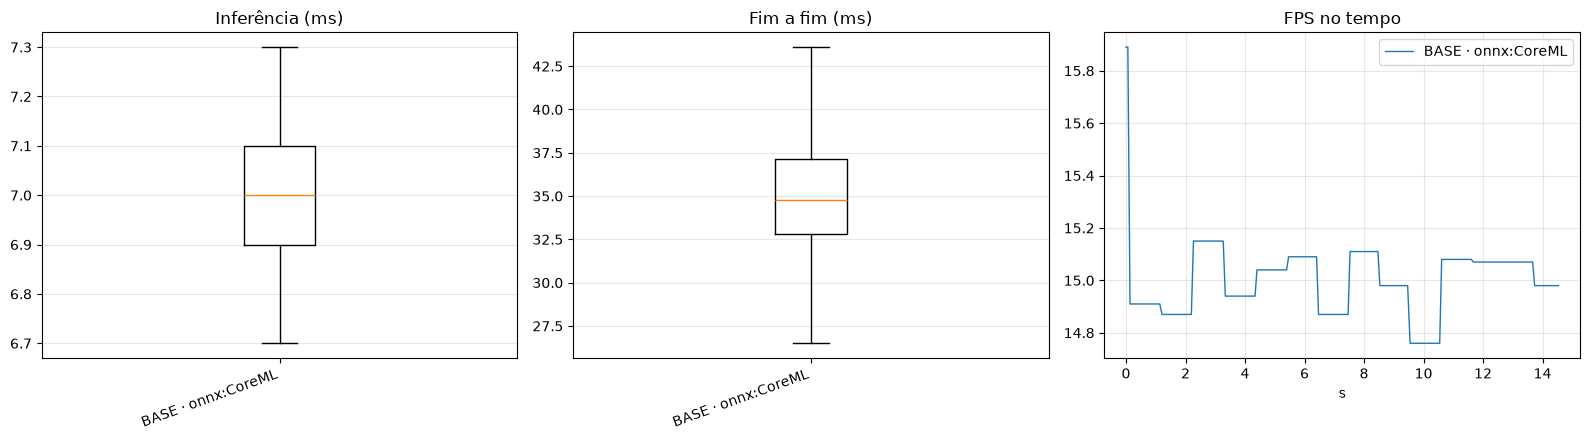

In [3]:
# Gráficos: distribuição das latências e FPS ao longo do tempo, por cenário
if frames is not None:
    dados = frames[frames["frame"] > 30].copy()
    dados["t"] = dados.groupby("sessao")["timestamp"].transform(lambda s: s - s.min())   # segundos desde o início da sessão

    fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5))
    modos = sorted(dados["cenario"].unique())                # um cenário por modo + dispositivo/provedor
    for eixo, coluna, titulo in [(eixos[0], "latencia_inferencia_ms", "Inferência (ms)"),
                                 (eixos[1], "latencia_fim_a_fim_ms", "Fim a fim (ms)")]:
        series = [dados.loc[dados["cenario"] == m, coluna].dropna() for m in modos]
        eixo.boxplot(series, showfliers=False)             # caixa = quartis; outliers ocultos
        eixo.set_xticks(range(1, len(modos) + 1), modos, rotation=20, ha="right")   # nomes dos cenários no eixo x
        eixo.set_title(titulo); eixo.grid(axis="y", alpha=0.3)
    for m in modos:                                        # FPS ao longo do tempo, uma linha por cenário
        sub = dados[dados["cenario"] == m]
        eixos[2].plot(sub["t"], sub["fps"], label=m, lw=1)
    eixos[2].set_title("FPS no tempo"); eixos[2].set_xlabel("s"); eixos[2].legend(); eixos[2].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

In [4]:
# Alertas de risco biológico: quantidade, classe e confiança
if alertas is not None and len(alertas):
    display(alertas.groupby("classe")["conf"].agg(["count", "mean", "min", "max"]).round(3))
    alertas["conf"].plot.hist(bins=20, title="Confiança dos alertas", figsize=(6, 3.5))
    plt.xlabel("confiança"); plt.show()
else:
    print("⏳ Ainda não há alertas registrados.")

⏳ Ainda não há alertas registrados.


## 7. Evidências

### 7.1 Demonstração com o iPhone pelo navegador (modo BASE)

A primeira sessão registrada da demonstração ao vivo usou o iPhone como câmera Wi-Fi: o Safari abriu a
página `/celular` pelo QR code (seção 5.4) e enviou os quadros em JPEG por HTTPS ao
`camera_server.py --fonte navegador`, executado no Mac. No terminal do VS Code, o `cliente_vscode.py`
reconheceu os quadros com o modelo oficial do projeto, o `best.pt` que treinei no Colab na Entrega 1,
exportado para `best.onnx` pelo `exportar_modelo.py` (seção 5.1) e executado com `--provedor auto`, que
no Mac resultou em `onnx:CoreMLExecutionProvider`. Nessa sessão, o `best.onnx` foi exportado a partir
do `best.pt` original; o `modelos/best_portavel.pt` versionado é a cópia do mesmo checkpoint, com os
mesmos pesos, e gera o ONNX pelo comando da seção 5.1. Os logs dessa sessão são os arquivos `logs/frames.csv`
e `logs/alertas.csv` lidos pelas células da seção 6, e os números abaixo vêm das saídas dessas células.

- **Volume:** 249 quadros em uma única sessão, todos no cenário `BASE · onnx:CoreML`.
- **FPS:** mediana de 15,0 quadros/s no cliente (p95 de 15,2), descartados os 30 primeiros quadros de
  aquecimento. É o mesmo valor do padrão de envio da página (15 quadros/s), então o ritmo foi ditado pelo
  celular, e não pela rede nem pelo modelo.
- **Inferência:** mediana de 7,0 ms (p95 de 7,3 ms), bem abaixo dos cerca de 67 ms entre dois quadros a
  15 quadros/s. Com o CoreML, a inferência deixou de ser o gargalo, como previsto na hipótese 4 da seção 6.
  A hipótese 1, sobre o PC sem GPU, ainda depende de uma sessão com `--provedor cpu`.
- **Rede:** RTT mediano de 4,3 ms no `GET /saude` (p95 de 13,4 ms).
- **Latência fim a fim:** mediana de 34,8 ms e p95 de 44,1 ms, da captura no celular até a exibição no
  Mac, já com o offset de relógio estimado pela página (incerteza de ±RTT/2, seção 5.4).
- **Classes detectadas:** pela coluna `classes` do `frames.csv`, a `caneca` aparece em 212 dos 249
  quadros; 30 quadros ficaram sem detecção e 7 tiveram `cerca`, cinco deles entre os seis primeiros
  quadros. Como não havia cerca na cena, trato esses casos como falsos positivos do início da captura.
- **Alertas:** nenhum quadro teve `cobra` ou `escorpiao`, e o `alertas.csv` da sessão só tem o cabeçalho;
  por isso a célula de alertas informa que ainda não há alertas registrados. O disparo do alerta foi
  verificado com o celular simulado (seção 5.4), e a demonstração com uma foto de cobra na tela é feita
  no vídeo.

A sessão durou cerca de 16 s, menos que os 2 minutos previstos no protocolo da seção 6. Considero esses
números a primeira medição do cenário com o celular, coerente com a simulação da seção 5.4, e não uma
medição de longa duração.

### 7.2 Prints

> ⏳ Pendente: capturo estes prints durante a gravação do vídeo de demonstração, com o mesmo cenário da
> seção 7.1, e comento aqui o que cada um mostra (caixas detectadas, FPS e latências exibidas).

| Cenário | Print | O que mostra |
|---|---|---|
| BASE · iPhone pelo Safari, caneca ao vivo | ⏳ `prints/celular_cliente.jpg` | janela do `cliente_vscode.py` com a caneca detectada, salva com a tecla **s** |
| BASE · iPhone pelo Safari, caixas no celular | ⏳ `prints/celular_iphone.jpg` | captura de tela do iPhone com as caixas desenhadas sobre a prévia da página `/celular` |
| Alerta de cobra (foto na tela) | ⏳ `prints/celular_alerta_cobra.jpg` | faixa vermelha de alerta, se o print for gravado na demonstração |
| BASE · webcam do PC | não executado | |
| BASE · ESP32-CAM | não executado | |
| BASE · Raspberry Pi 5 | não executado | |
| PLUS · Hailo-8L | não executado | |

No vídeo de demonstração, também abro a rota `/saude` no navegador do celular, o que comprova que o
dispositivo está acessível pela rede Wi-Fi.

## 8. Plus: Raspberry Pi 5 + Hailo-8L

> **Não executado no hardware.** Implementei o backend (`backends/hailo_backend.py`), a opção
> `--inferencia hailo` do `camera_server.py` e o guia de conversão (`hailo/README_conversao.md`), mas até a
> entrega não executei esse caminho no Raspberry Pi 5 com o Hailo-8L nem compilei o `best.hef`. Esta seção
> registra o que pretendo medir; não há resultados.

A conversão `best.pt → ONNX → .hef` está descrita em `hailo/README_conversao.md`; o ONNX de entrada do
DFC é o mesmo gerado pelo `exportar_modelo.py` (seção 5.1).

**O que será medido:**

| Medida | Como | Para que serve |
|---|---|---|
| FPS e latência só da NPU | `hailortcli benchmark best.hef` | limite do chip isolado |
| FPS e latência fim a fim do PLUS com Hailo | logs do cliente (seção 6) com `--inferencia hailo` | quanto do tempo vai para captura, codificação JPEG e Wi-Fi |
| FPS e latência do plano B | logs do cliente com `--inferencia onnx --provedor cpu` no Pi | comparação entre a CPU do Pi e a NPU |
| mAP@0.5 por classe, FP32 (Colab) × INT8 (Hailo) | mesmo conjunto de teste da Entrega 1, antes e depois da quantização | efeito da quantização em cada uma das seis classes |

A referência do modo BASE no PC é a sessão medida na seção 7.1.

> Hipótese: o INT8 penaliza mais as classes de objeto pequeno (`escorpiao`, `cobra`). Se isso se
> confirmar, o rover vai precisar de mais resolução de entrada ou de um segundo estágio de classificação
> para as classes de segurança.

## 9. Conclusões

- **Funcionalidade:** a câmera coleta as imagens, o Wi-Fi as transmite e o VS Code reconhece os objetos
  com o modelo da Entrega 1. Testei esse fluxo com o iPhone pelo Safari no macOS: na sessão registrada,
  o modelo oficial treinado no Colab, exportado para `best.onnx` e executado em CoreML, reconheceu a
  `caneca` em 212 de 249 quadros, e as caixas voltaram à tela do celular (seção 7.1). A ESP32-CAM, o
  Raspberry Pi 5 e a webcam do PC estão implementados com as mesmas rotas e o mesmo cliente, mas não
  foram testados. Linux e Windows estão previstos no código (`--dispositivo`, `--provedor` e `pathlib`),
  sem teste.
- **Wi-Fi:** na sessão com o iPhone, o RTT mediano foi de 4,3 ms e a latência fim a fim ficou em 34,8 ms
  de mediana e 44,1 ms no p95, com o FPS preso aos 15 quadros/s enviados pela página. A recuperação após
  quedas de sinal foi verificada com o celular simulado (seção 5.4).
- **Alerta:** o disparo para `cobra` e `escorpiao` foi verificado com o celular simulado (seção 5.4); a
  demonstração com uma foto de cobra na tela é feita no vídeo. O `alertas.csv` versionado, da sessão com
  o iPhone, não tem alertas.
- **Plus:** implementado (código e guia de conversão), não executado no hardware. O ganho de latência
  da NPU e a independência do PC no campo continuam como hipóteses, e a seção 8 descreve como pretendo
  medi-los.
- **Limitações:** dataset pequeno (cerca de 32 imagens de treino por classe), sessão com o iPhone curta
  (cerca de 16 s), latência fim a fim dependente de NTP ou da correção de relógio da página, câmeras
  além do iPhone e o Hailo sem teste, efeito do INT8 não medido e alertas verificados só com fotos,
  não com animais reais.